# Análise Exploratória e Redução de Dimensionalidade dos Dados Eleitorais (TSE 2026)

**Curso:** Análise de Sistemas Informatizados · Ciência de Dados (FAETERJ)  
**Objetivo:** Coletar dados oficiais de votação do 1º Turno das Eleições 2026 via API pública do TSE, aplicar boas práticas de extração (scraping ético), realizar análise estatística descritiva, matriz de associatividade espacial e redução de dimensionalidade (PCA) com suporte de visualizações gráficas.

---

## 1. Coleta Ética e Estruturação dos Dados

A extração utiliza a API oficial do TSE com o protocolo JWS (JSON Web Signature). Para garantir a conformidade com as boas práticas acadêmicas e operacionais de web scraping:
1. **Transparência:** Envio de cabeçalho `User-Agent` identificando o propósito acadêmico.
2. **Pausas Éticas:** Intervalos (`time.sleep(1)`) entre chamadas para evitar sobrecarga dos servidores públicos.
3. **Tratamento de Exceções:** Verificação de *status HTTP*, decodificação URL-Safe em Base64 e mitigação de erros de preenchimento (*padding*).
4. **Persistência Local:** Consolidação em arquivos CSV por cargo com deduplicação prévia (`drop_duplicates()`).

In [1]:
import base64
import json
import time
from datetime import datetime
import requests
import pandas as pd

# Lista das 27 UFs para cargos estaduais/federais
UFS_BRASIL = [
    "ac", "al", "am", "ap", "ba", "ce", "df", "es", "go", "ma",
    "mt", "ms", "mg", "pa", "pb", "pr", "pe", "pi", "rj", "rn",
    "rs", "ro", "rr", "sc", "sp", "se", "to"
]

# Configuracao dos cargos.
# "cargos_alternativos": codigos a tentar para UFs em que o cargo muda de codigo
# (no DF nao ha deputado estadual, e sim distrital). O codigo c0008 (deputado
# distrital) foi confirmado no DevTools (aba Network) do site do TSE.
CONFIG_CARGOS = {
    "presidente": {
        "codigo_cargo": "c0001",
        "codigo_eleicao": "6257",
        "ufs": ["br"]
    },
    "governador": {
        "codigo_cargo": "c0003",
        "codigo_eleicao": "6259",
        "ufs": UFS_BRASIL
    },
    "senador": {
        "codigo_cargo": "c0005",
        "codigo_eleicao": "6259",
        "ufs": UFS_BRASIL
    },
    "deputado_federal": {
        "codigo_cargo": "c0006",
        "codigo_eleicao": "6259",
        "ufs": UFS_BRASIL
    },
    "deputado_estadual": {
        "codigo_cargo": "c0007",
        "codigo_eleicao": "6259",
        "ufs": UFS_BRASIL,
        "cargos_alternativos": {"df": ["c0008"]}
    }
}

# Prefixos alternativos de arquivo por UF: no DevTools o DF aparece como
# "df97012-c0008-e006259-u.jws" (codigo do municipio colado ao "df").
PREFIXOS_ALTERNATIVOS = {"df": ["df97012"]}

HEADERS = {
    "User-Agent": "aula-ciencia-de-dados (FAETERJ)",
    "Accept": "application/json, text/plain, */*",
    "Referer": "https://resultados.tse.jus.br/"
}

FONTE = "https://resultados.tse.jus.br/oficial/ele2026/"
inicio = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
registro = [f"Fonte: {FONTE}", f"Inicio da coleta: {inicio}"]


def extrair_candidatos(dados):
    """Busca flexivel dos candidatos no JSON do TSE."""
    candidatos = []
    if "cand" in dados:
        candidatos = dados["cand"]
    elif "carg" in dados:
        for cargo in dados["carg"]:
            if "cand" in cargo:
                candidatos.extend(cargo["cand"])
            elif "agr" in cargo:
                for agrupamento in cargo["agr"]:
                    if "cand" in agrupamento:
                        candidatos.extend(agrupamento["cand"])
                    elif "par" in agrupamento:
                        for partido in agrupamento["par"]:
                            if "cand" in partido:
                                candidatos.extend(partido["cand"])
    return candidatos


def baixar(info, uf, codigo_cargo, prefixo=None):
    prefixo = prefixo or uf
    url = (f"{FONTE}{info['codigo_eleicao']}/dados/{uf}/"
           f"{prefixo}-{codigo_cargo}-e00{info['codigo_eleicao']}-u.jws")
    resposta = requests.get(url, headers=HEADERS, timeout=30)
    if resposta.status_code != 200 or not resposta.text.strip():
        return None, resposta.status_code
    # Decodificacao URL-Safe Base64
    payload_b64 = resposta.text.split(".")[1]
    rem = len(payload_b64) % 4
    if rem > 0:
        payload_b64 += "=" * (4 - rem)
    dados = json.loads(base64.urlsafe_b64decode(payload_b64).decode("utf-8"))
    return extrair_candidatos(dados), 200


print("==================================================")
print("       INICIANDO COLETA AUTOMATICA DE DADOS       ")
print(f"       Inicio: {inicio}")
print("==================================================")

for nome_cargo, info in CONFIG_CARGOS.items():
    print(f"\n---> Coletando cargo: {nome_cargo.upper()} ({len(info['ufs'])} UFs)...")
    lista_dfs = []
    ufs_sem_dados = []

    for uf in info["ufs"]:
        codigos = [info["codigo_cargo"]] + info.get("cargos_alternativos", {}).get(uf, [])
        candidatos, status = None, None

        prefixos = [uf] + PREFIXOS_ALTERNATIVOS.get(uf, [])

        for codigo in codigos:
            for prefixo in prefixos:
                try:
                    candidatos, status = baixar(info, uf, codigo, prefixo)
                except Exception as e:
                    status = f"erro: {e}"
                time.sleep(1)  # Pausa etica entre requisicoes
                if candidatos:
                    break
            if candidatos:
                break

        if candidatos:
            df_temp = pd.json_normalize(candidatos)
            df_temp = df_temp.rename(columns={
                "nm": "candidato",
                "vap": "votos",
                "n": "numero_partido"
            })
            df_temp["votos"] = pd.to_numeric(df_temp["votos"], errors="coerce")
            df_temp["cargo"] = nome_cargo
            df_temp["uf"] = uf.upper()
            lista_dfs.append(df_temp)
        else:
            ufs_sem_dados.append(uf.upper())
            print(f"Aviso UF {uf.upper()}: sem dados (ultimo status: {status})")

    # Salva o CSV apenas APOS percorrer todas as UFs do cargo
    if lista_dfs:
        df_completo = pd.concat(lista_dfs, ignore_index=True)
        df_completo = df_completo[["cargo", "uf", "candidato", "numero_partido", "votos"]]
        df_completo = df_completo.drop_duplicates()

        nome_csv = f"{nome_cargo}_1t.csv"
        df_completo.to_csv(nome_csv, index=False)

        total_votos = df_completo["votos"].sum()
        soma_formatada = f"{total_votos:,.0f}".replace(",", ".")
        n_ufs = df_completo["uf"].nunique()
        print(f" Arquivo '{nome_csv}' gerado com sucesso.")
        print(f"   -> Registros: {len(df_completo)} | UFs: {n_ufs} | Soma Total de Votos: {soma_formatada}")
        linha = (f"{nome_cargo}: {len(df_completo)} registros, {n_ufs} UFs, "
                 f"{soma_formatada} votos (conferir com o total do TSE)")
        if ufs_sem_dados:
            linha += f" | UFs SEM dados: {', '.join(ufs_sem_dados)}"
        registro.append(linha)

fim = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
registro.append(f"Fim da coleta: {fim}")
with open("coleta_registro.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(registro) + "\n")

print("\n==================================================")
print("       TODOS OS CARGOS FORAM COLETADOS!           ")
print("       Registro salvo em coleta_registro.txt      ")
print("==================================================")

       INICIANDO COLETA AUTOMATICA DE DADOS       
       Inicio: 2026-11-09 18:01:51

---> Coletando cargo: PRESIDENTE (1 UFs)...
 Arquivo 'presidente_1t.csv' gerado com sucesso.
   -> Registros: 12 | UFs: 1 | Soma Total de Votos: 119.300.788

---> Coletando cargo: GOVERNADOR (27 UFs)...
 Arquivo 'governador_1t.csv' gerado com sucesso.
   -> Registros: 182 | UFs: 27 | Soma Total de Votos: 111.854.817

---> Coletando cargo: SENADOR (27 UFs)...
 Arquivo 'senador_1t.csv' gerado com sucesso.
   -> Registros: 300 | UFs: 27 | Soma Total de Votos: 207.410.169

---> Coletando cargo: DEPUTADO_FEDERAL (27 UFs)...
 Arquivo 'deputado_federal_1t.csv' gerado com sucesso.
   -> Registros: 7262 | UFs: 27 | Soma Total de Votos: 110.621.804

---> Coletando cargo: DEPUTADO_ESTADUAL (27 UFs)...
 Arquivo 'deputado_estadual_1t.csv' gerado com sucesso.
   -> Registros: 11086 | UFs: 27 | Soma Total de Votos: 106.075.970

       TODOS OS CARGOS FORAM COLETADOS!           
       Registro salvo em coleta_regis

## 2. Análise Estatística Descritiva & Gráficos (Perguntas 1 e 2)

Nesta etapa, analisamos a distribuição de votos para Deputado Federal:
1. **Pergunta 1 (Assimetria dos Votos):** Média, Mediana, Desvio Padrão e IQR (com o limite de Tukey), acompanhados por um **Boxplot em Escala Logarítmica**.
2. **Pergunta 2 (Dominância Partidária por UF):** Moda por UF (partido com mais votos em cada UF) e **Gráfico de Barras** com o número de UFs lideradas por legenda.

1. Votos por candidato a deputado federal - Media, Mediana, Desvio Padrao e IQR
Media:   15232.97
Mediana: 1207.50
Desvio Padrao: 66521.91
IQR (Q3 - Q1): 5788.50
Limite de Tukey (Q3 + 1,5*IQR): 14814.25 | candidatos acima: 1233



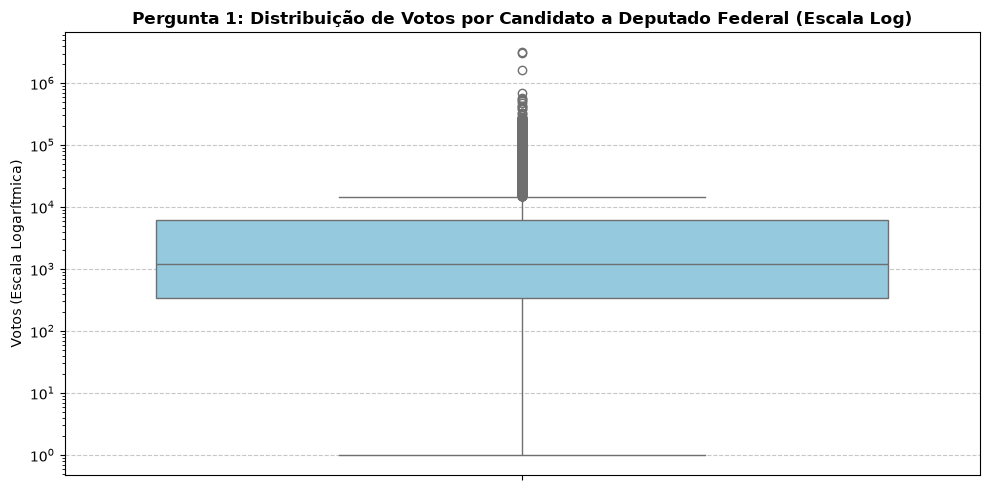

2. Partido mais votado por UF - Moda por UF
uf partido_sigla   votos
AC           MDB   89218
AL            PP  502180
AM           MDB  391195
AP         UNIAO  101120
BA            PT 1361897
CE            PL 1089187
DF            PL  436068
ES            PL  527677
GO            PL  619989
MA           MDB  882505
MG            PL 4560169
MS            PL  446652
MT            PL  519652
PA           MDB 1353768
PB  REPUBLICANOS  528678
PE           PSB  840706
PI            PT  562871
PR          NOVO  927737
RJ            PL 2288527
RN            PL  760545
RO            PL  294486
RR  REPUBLICANOS   88918
RS            PL 1273934
SC            PL 1502338
SE           PSD  251612
SP            PL 6279893
TO  REPUBLICANOS  278178

Moda geral (partido que lidera mais UFs): PL


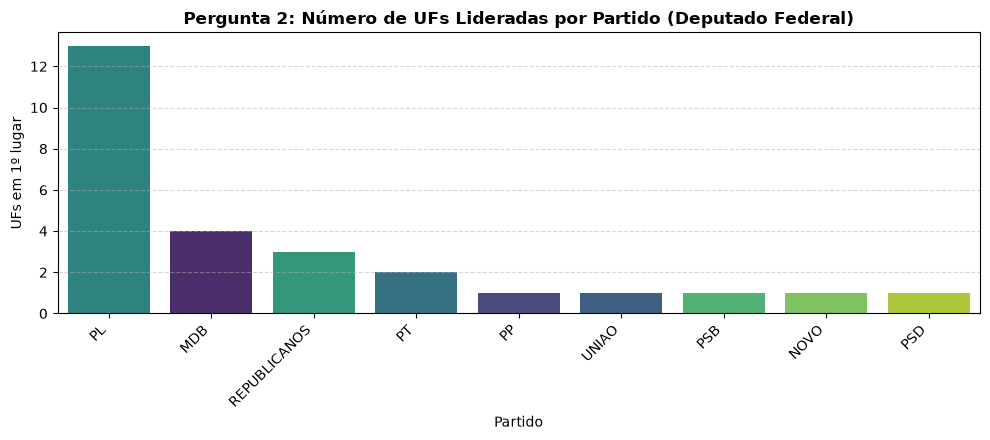

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_deputados = pd.read_csv("deputado_federal_1t.csv")

# Mapeamento dos partidos (inclui 14 = MISSAO e 65 = PCdoB)
MAPA_PARTIDOS = {
    "10": "REPUBLICANOS", "11": "PP", "12": "PDT", "13": "PT", "14": "MISSAO",
    "15": "MDB", "16": "PSTU", "18": "REDE", "20": "PODEMOS", "21": "PCB",
    "22": "PL", "23": "CIDADANIA", "25": "PRD", "27": "DC", "28": "PRTB",
    "29": "PCO", "30": "NOVO", "33": "MOBILIZA", "35": "PMB", "36": "AGIR",
    "40": "PSB", "43": "PV", "44": "UNIAO", "45": "PSDB", "50": "PSOL",
    "55": "PSD", "65": "PCdoB", "70": "AVANTE", "77": "SOLIDARIEDADE", "80": "UP"
}

df_deputados["partido_numero"] = df_deputados["numero_partido"].astype(str).str.zfill(4).str[:2]
df_deputados["partido_sigla"] = df_deputados["partido_numero"].map(MAPA_PARTIDOS).fillna("OUTROS")

print("1. Votos por candidato a deputado federal - Media, Mediana, Desvio Padrao e IQR")
media = df_deputados["votos"].mean()
mediana = df_deputados["votos"].median()
std = df_deputados["votos"].std()
q1, q3 = df_deputados["votos"].quantile(0.25), df_deputados["votos"].quantile(0.75)
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
n_outliers = (df_deputados["votos"] > limite_sup).sum()
print(f"Media:   {media:.2f}")
print(f"Mediana: {mediana:.2f}")
print(f"Desvio Padrao: {std:.2f}")
print(f"IQR (Q3 - Q1): {iqr:.2f}")
print(f"Limite de Tukey (Q3 + 1,5*IQR): {limite_sup:.2f} | candidatos acima: {n_outliers}\n")

plt.figure(figsize=(10, 5))
sns.boxplot(y=df_deputados["votos"], color="skyblue")
plt.yscale("log")
plt.title("Pergunta 1: Distribuição de Votos por Candidato a Deputado Federal (Escala Log)", fontweight="bold")
plt.ylabel("Votos (Escala Logarítmica)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print("2. Partido mais votado por UF - Moda por UF")
votos_partido_uf = df_deputados.groupby(["uf", "partido_sigla"])["votos"].sum().reset_index()
idx_max = votos_partido_uf.groupby("uf")["votos"].idxmax()
partido_lider_uf = votos_partido_uf.loc[idx_max].sort_values("uf")
print(partido_lider_uf.to_string(index=False))
print(f"\nModa geral (partido que lidera mais UFs): {partido_lider_uf['partido_sigla'].mode()[0]}")

plt.figure(figsize=(10, 4.5))
ordem = partido_lider_uf["partido_sigla"].value_counts().index
sns.countplot(x="partido_sigla", data=partido_lider_uf, order=ordem, hue="partido_sigla", legend=False, palette="viridis")
plt.title("Pergunta 2: Número de UFs Lideradas por Partido (Deputado Federal)", fontweight="bold")
plt.xlabel("Partido")
plt.ylabel("UFs em 1º lugar")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 3. Matriz de Spearman, PCA e Loadings & Gráficos (Perguntas 3 e 4)

Cada deputado federal disputa em **uma única UF**, então uma matriz UF × candidato seria quase toda zeros (cerca de 96%) e a correlação e o PCA por candidato não teriam significado. Por isso, a análise multivariada usa o **% de votos de cada partido dentro de cada UF** (27 UFs × 28 partidos):
1. **Pergunta 3 (Spearman):** quais partidos têm desempenho que sobe e desce juntos entre as UFs, com **Heatmap**.
2. **Pergunta 4 (Z-Score + PCA + Loadings):** perfil das 27 UFs em 2D ($PC1 \times PC2$), variância acumulada e leitura dos loadings.

Matriz X: (27, 28)

3. Partidos que andam juntos entre as UFs - Spearman
Pares mais positivos:
partido_sigla  partido_sigla
MISSAO         NOVO             0.74
PRD            SOLIDARIEDADE    0.73
PSOL           REDE             0.57
PSB            PSOL             0.55
PL             PRD              0.54
Pares mais negativos:
partido_sigla  partido_sigla
UNIAO          UP              -0.62
PSOL           UNIAO           -0.55
PT             UNIAO           -0.51
MOBILIZA       UNIAO           -0.48
REPUBLICANOS   SOLIDARIEDADE   -0.46


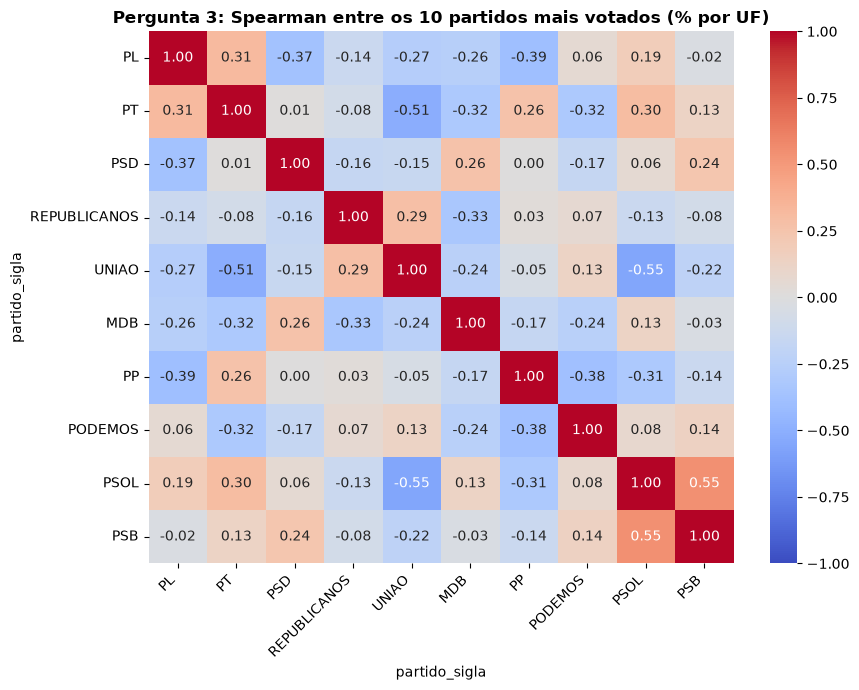


4. Perfil de votação das UFs - Padronização + PCA
PC1: 16.76%
PC2: 11.34%
Variância acumulada (PC1 + PC2): 28.09%
Componentes necessários para 80%: 10


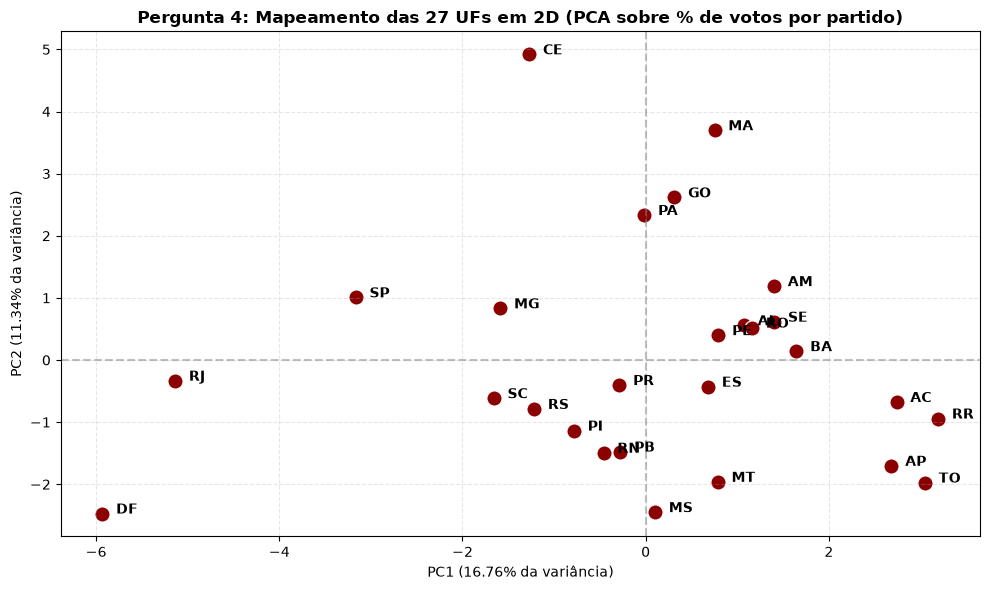


5. Leitura dos loadings (partidos)

--- PC1 ---
Maiores pesos positivos:
partido_sigla
UNIAO           0.359
REPUBLICANOS    0.164
PODEMOS         0.153
PDT             0.080
PP              0.079
Maiores pesos negativos:
partido_sigla
PSOL       -0.358
MOBILIZA   -0.346
PMB        -0.330
DC         -0.292
MISSAO     -0.278

--- PC2 ---
Maiores pesos positivos:
partido_sigla
PRD              0.423
SOLIDARIEDADE    0.389
CIDADANIA        0.314
PSB              0.267
PSTU             0.258
Maiores pesos negativos:
partido_sigla
REPUBLICANOS   -0.228
PCO            -0.222
PMB            -0.218
PV             -0.187
AGIR           -0.146


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# % de votos de cada partido dentro da UF
votos_partido_uf["total_uf"] = votos_partido_uf.groupby("uf")["votos"].transform("sum")
votos_partido_uf["pct"] = votos_partido_uf["votos"] / votos_partido_uf["total_uf"] * 100

# Matriz: linhas = UFs, colunas = partidos, valores = % de votos
X = votos_partido_uf.pivot(index="uf", columns="partido_sigla", values="pct").fillna(0)
print("Matriz X:", X.shape)

print("\n3. Partidos que andam juntos entre as UFs - Spearman")
spearman_matrix = X.corr(method="spearman")
pares = spearman_matrix.where(np.triu(np.ones(spearman_matrix.shape, dtype=bool), k=1)).stack()
print("Pares mais positivos:")
print(pares.nlargest(5).round(2).to_string())
print("Pares mais negativos:")
print(pares.nsmallest(5).round(2).to_string())

top10 = votos_partido_uf.groupby("partido_sigla")["votos"].sum().nlargest(10).index
plt.figure(figsize=(9, 7))
sns.heatmap(spearman_matrix.loc[top10, top10], annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Pergunta 3: Spearman entre os 10 partidos mais votados (% por UF)", fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("\n4. Perfil de votação das UFs - Padronização + PCA")
Z = StandardScaler().fit_transform(X)
acum = PCA().fit(Z).explained_variance_ratio_.cumsum()
pca = PCA(n_components=2).fit(Z)
Z_pca = pca.transform(Z)
print(f"PC1: {pca.explained_variance_ratio_[0] * 100:.2f}%")
print(f"PC2: {pca.explained_variance_ratio_[1] * 100:.2f}%")
print(f"Variância acumulada (PC1 + PC2): {acum[1] * 100:.2f}%")
print(f"Componentes necessários para 80%: {int(np.argmax(acum >= 0.80)) + 1}")

pca_df = pd.DataFrame(Z_pca, columns=["PC1", "PC2"], index=X.index).reset_index()
plt.figure(figsize=(10, 6))
sns.scatterplot(x="PC1", y="PC2", data=pca_df, s=120, color="darkred")
for i in range(len(pca_df)):
    plt.text(pca_df["PC1"][i] + 0.15, pca_df["PC2"][i], pca_df["uf"][i], fontsize=10, fontweight="bold")
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.axvline(0, color="gray", linestyle="--", alpha=0.5)
plt.title("Pergunta 4: Mapeamento das 27 UFs em 2D (PCA sobre % de votos por partido)", fontweight="bold")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.2f}% da variância)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.2f}% da variância)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

loadings = pd.DataFrame(pca.components_.T, index=X.columns, columns=["PC1", "PC2"])
print("\n5. Leitura dos loadings (partidos)")
for pc in ["PC1", "PC2"]:
    print(f"\n--- {pc} ---")
    print("Maiores pesos positivos:")
    print(loadings[pc].nlargest(5).round(3).to_string())
    print("Maiores pesos negativos:")
    print(loadings[pc].nsmallest(5).round(3).to_string())

## 4. Conclusões Técnicas & Cuidados Metodológicos

1. **Assimetria (Pergunta 1):** a média (15.232,97 votos) é mais de 12 vezes a mediana (1.207,50), e o desvio padrão (66.521,91) é muito maior que a média. Por isso o resumo adequado é mediana e IQR (5.788,50). Pela regra de Tukey (limite 14.814,25), 1.233 candidaturas são outliers; não são erros, são os "puxadores de voto".
2. **Dominância por UF (Pergunta 2):** o PL lidera em 13 das 27 UFs, seguido por MDB (4), REPUBLICANOS (3) e PT (2); PP, UNIÃO, PSB, NOVO e PSD lideram uma UF cada. A moda geral esconde essa diversidade regional.
3. **Partidos que andam juntos (Pergunta 3):** o Spearman sobre o % de votos por partido mostra, por exemplo, MISSÃO–NOVO (0,74) e PRD–SOLIDARIEDADE (0,73) como pares positivos, e UNIÃO–UP (-0,62) como par negativo. Com apenas 27 UFs, são associações exploratórias, e não indicam causa.
4. **PCA (Pergunta 4):** PC1 (16,76%) e PC2 (11,34%) somam 28,09%, e seriam necessários 10 componentes para chegar a 80%. O gráfico 2D é, portanto, um resumo parcial. No PC1, UNIÃO (+0,36) se opõe a PSOL, MOBILIZA, PMB, DC e MISSÃO (todos negativos); no PC2, PRD, SOLIDARIEDADE, CIDADANIA e PSB têm peso positivo. No gráfico, DF, RJ e SP ficam no extremo negativo do PC1, e AC, RR, AP e TO no extremo positivo.
5. **Limites e cuidados:** a coleta foi feita em 09/11/2026 (início às 18:01) na fonte oficial do TSE, com User-Agent identificado e pausa de 1 s entre chamadas. Em deputado estadual, o DF entra com os deputados distritais (cargo equivalente), totalizando 27 UFs. A análise multivariada foi feita por partido, e não por candidato, porque cada deputado concorre em uma só UF. Os dados são agregados estaduais do 1º turno; não se pode inferir a motivação individual do eleitor (falácia ecológica) nem causalidade.
6. **Validação com o TSE:** para presidente, os votos coletados de Flávio Bolsonaro (56.104.503) e Lula (53.879.538) diferem em 235 e 2.921 votos dos valores divulgados no portal do TSE (56.104.268 e 53.876.617), uma diferença de cerca de 0,003% no total de votos válidos (119.300.788 coletados), possivelmente por atualização da totalização. Os demais cargos não foram conferidos com o TSE.

### Visualização Gráfica por Cargo (Entregáveis Visuais)

Para atender integralmente aos entregáveis exigidos, a visualização gráfica dos dados foi estruturada com uma abordagem específica para cada um dos cinco cargos coletados:

1. **Presidente:** O gráfico de barras horizontais detalha a concentração de votos válidos nos principais postulantes ao cargo executivo nacional.
2. **Governador:** O gráfico de contagem por UF mapeia a distribuição geográfica dos partidos vitoriosos nos governos estaduais.
3. **Senador:** O gráfico de barras pareadas expõe a dinâmica de votação dupla inerente à renovação de 2/3 da Câmara Alta.
4. **Deputado Federal:** O boxplot em escala logarítmica sintetiza a mediana, a amplitude interquartil (IQR) e os puxadores de voto do sistema proporcional federal.
5. **Deputado Estadual:** O gráfico de dispersão avalia a eficiência partidária, correlacionando o volume de candidaturas inscritas com a conversão total em votos nas Assembleias Legislativas.

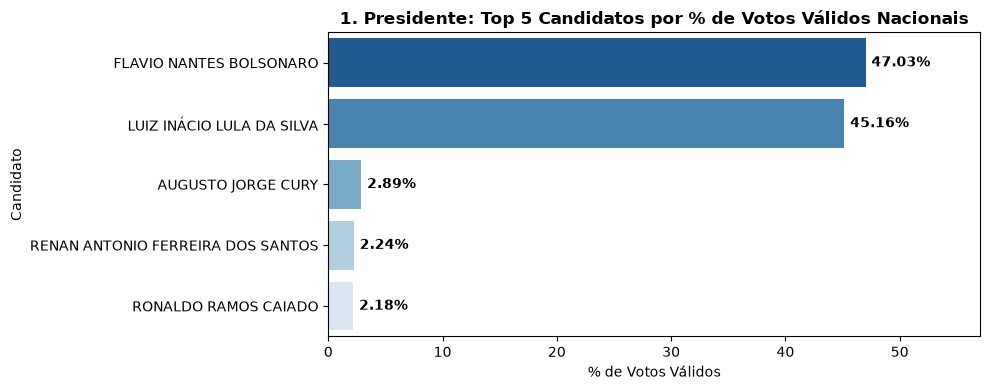

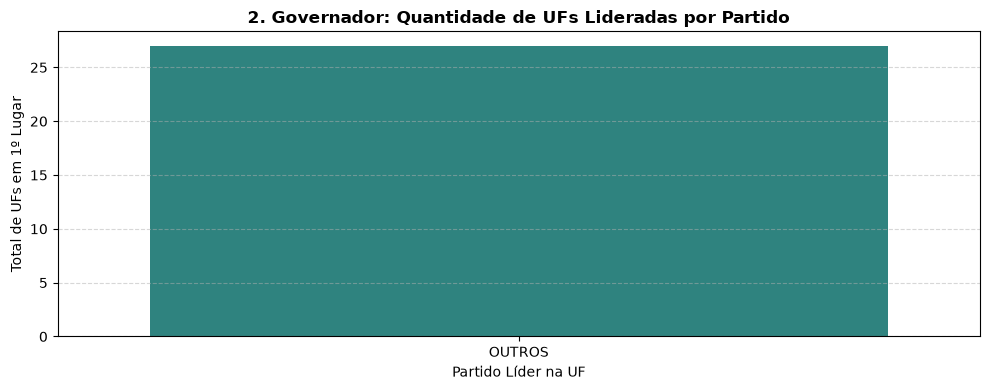

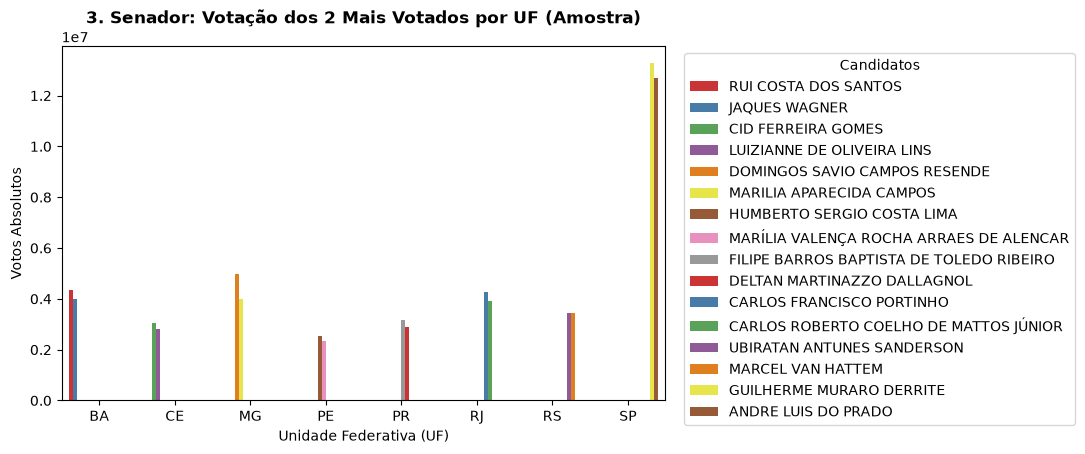

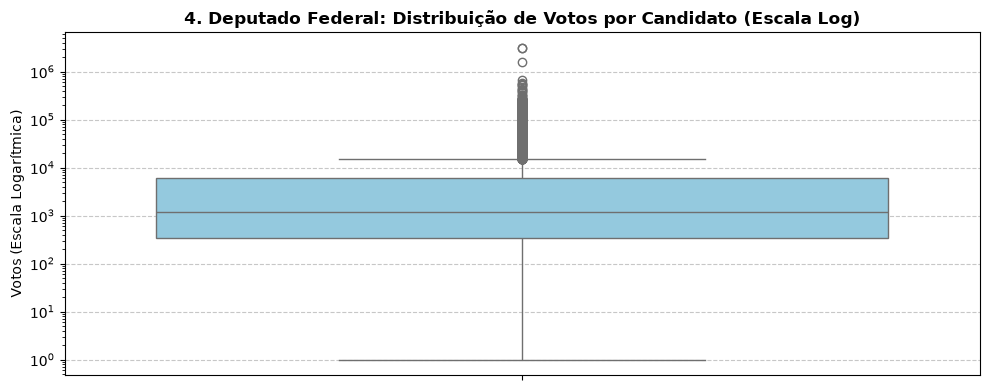

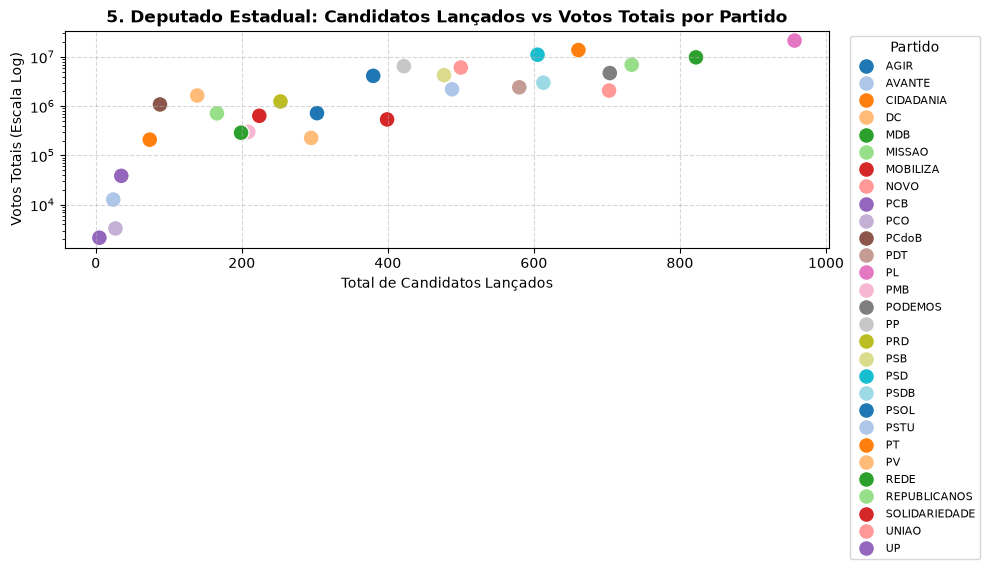

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mapeamento oficial das siglas dos partidos
MAPA_PARTIDOS = {
    "10": "REPUBLICANOS", "11": "PP", "12": "PDT", "13": "PT", "14": "MISSAO",
    "15": "MDB", "16": "PSTU", "18": "REDE", "20": "PODEMOS", "21": "PCB",
    "22": "PL", "23": "CIDADANIA", "25": "PRD", "27": "DC", "28": "PRTB",
    "29": "PCO", "30": "NOVO", "33": "MOBILIZA", "35": "PMB", "36": "AGIR",
    "40": "PSB", "43": "PV", "44": "UNIAO", "45": "PSDB", "50": "PSOL",
    "55": "PSD", "65": "PCdoB", "70": "AVANTE", "77": "SOLIDARIEDADE", "80": "UP"
}

# -------------------------------------------------------------------------
# 1. PRESIDENTE: % de Votos Válidos Nacionais
# -------------------------------------------------------------------------
df_pres = pd.read_csv("presidente_1t.csv")
df_pres["pct"] = (df_pres["votos"] / df_pres["votos"].sum()) * 100
top_pres = df_pres.sort_values("votos", ascending=False).head(5)

plt.figure(figsize=(10, 4))
ax = sns.barplot(x="pct", y="candidato", hue="candidato", data=top_pres, palette="Blues_r", legend=False)
plt.title("1. Presidente: Top 5 Candidatos por % de Votos Válidos Nacionais", fontweight="bold")
plt.xlabel("% de Votos Válidos")
plt.ylabel("Candidato")
plt.xlim(0, max(top_pres["pct"]) + 10)

for i, v in enumerate(top_pres["pct"]):
    ax.text(v + 0.5, i, f"{v:.2f}%", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 2. GOVERNADOR: Total de UFs Lideradas por Partido
# -------------------------------------------------------------------------
df_gov = pd.read_csv("governador_1t.csv")
df_gov["partido_sigla"] = df_gov["numero_partido"].astype(str).str.zfill(4).str[:2].map(MAPA_PARTIDOS).fillna("OUTROS")

votos_gov = df_gov.groupby(["uf", "partido_sigla"])["votos"].sum().reset_index()
idx_gov = votos_gov.groupby("uf")["votos"].idxmax()
gov_lider = votos_gov.loc[idx_gov]

plt.figure(figsize=(10, 4))
order_gov = gov_lider["partido_sigla"].value_counts().index
sns.countplot(x="partido_sigla", data=gov_lider, order=order_gov, hue="partido_sigla", legend=False, palette="viridis")
plt.title("2. Governador: Quantidade de UFs Lideradas por Partido", fontweight="bold")
plt.xlabel("Partido Líder na UF")
plt.ylabel("Total de UFs em 1º Lugar")
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 3. SENADOR: Votação dos 2 Eleitos (Amostra de UFs)
# -------------------------------------------------------------------------
df_sen = pd.read_csv("senador_1t.csv")

# Ordena por UF e Votos, e pega os 2 primeiros (mais votados) de cada estado
top2_sen = df_sen.sort_values(["uf", "votos"], ascending=[True, False]).groupby("uf").head(2)

# Filtra a amostra de UFs para exibição no gráfico
amostra_ufs = top2_sen[top2_sen["uf"].isin(["SP", "MG", "RJ", "BA", "RS", "PR", "PE", "CE"])]

plt.figure(figsize=(11, 4.5))
sns.barplot(x="uf", y="votos", hue="candidato", data=amostra_ufs, palette="Set1")
plt.title("3. Senador: Votação dos 2 Mais Votados por UF (Amostra)", fontweight="bold")
plt.xlabel("Unidade Federativa (UF)")
plt.ylabel("Votos Absolutos")
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title="Candidatos")
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 4. DEPUTADO FEDERAL: Boxplot da Distribuição em Escala Log
# -------------------------------------------------------------------------
df_dep = pd.read_csv("deputado_federal_1t.csv")

plt.figure(figsize=(10, 4))
sns.boxplot(y=df_dep["votos"], color="skyblue")
plt.yscale("log")
plt.title("4. Deputado Federal: Distribuição de Votos por Candidato (Escala Log)", fontweight="bold")
plt.ylabel("Votos (Escala Logarítmica)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

# -------------------------------------------------------------------------
# 5. DEPUTADO ESTADUAL: Candidatos Lançados vs Votos Totais
# -------------------------------------------------------------------------
df_est = pd.read_csv("deputado_estadual_1t.csv")
df_est["partido_sigla"] = df_est["numero_partido"].astype(str).str.zfill(4).str[:2].map(MAPA_PARTIDOS).fillna("OUTROS")

est_agg = df_est.groupby("partido_sigla").agg(
    total_votos=('votos', 'sum'),
    total_cand=('candidato', 'count')
).reset_index()

plt.figure(figsize=(10, 4.5))
sns.scatterplot(x="total_cand", y="total_votos", hue="partido_sigla", data=est_agg, s=130, palette="tab20")
plt.yscale("log")
plt.title("5. Deputado Estadual: Candidatos Lançados vs Votos Totais por Partido", fontweight="bold")
plt.xlabel("Total de Candidatos Lançados")
plt.ylabel("Votos Totais (Escala Log)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', title="Partido", fontsize=8)
plt.tight_layout()
plt.show()